# Beyond the Answer
## Selecting and testing an internal intervention

**Does changing a language model's internal state change its decision, who benefits, and does prompting do the same thing?**

This notebook follows one intervention from exploratory selection to a fixed comparison on new negotiation cases. It uses real, independently verified model responses. You can rerun the analysis, examine individual answers, and download every attempt. The figures below are calculated from those records, not illustrative data.

**The finding in brief:** with the same input prompt, the edit shifted 13 of 33 valid decisions from acceptance to counteroffering. Reversing it turned all ten baseline counteroffers into acceptances; three random edits changed two, one and two decisions. The edited offers requested more for the buyer and less for the supplier. They were rejected, so the behavioral effect did not deliver the intended payoff improvement. Prompting also lowered payoffs against baseline, but less than the edit. Wording tests and two exact fresh-session repeats distinguish transfer from execution stability.

### Start here

Read the saved outputs, or choose **Run → Run All Cells**. The default run needs a CPU only. It does not load a language model, connect to a provider, or spend GPU credits. Installation instructions are in `README.md`.

By the end you should be able to:

1. distinguish an edit's intended behavior from its measured consequences;
2. understand why a layer and strength were selected, including failed candidates;
3. compare a fixed intervention with baseline, prompting and controls;
4. inspect robustness, invalid answers and the records behind each result;
5. identify which inputs and scoring rules to change for another study.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / "source_manifest.json").exists(), "Open this notebook from its own folder."
sys.path.insert(0, str(ROOT))
import notebook_support as nb

nb.verify_sources()

Matplotlib is building the font cache; this may take a moment.


{'files_checked': 1062, 'status': 'All bundled inputs match', 'model_runs': 0}

## 1. Specify the change and the consequences

The model acts as a buyer deciding whether to accept a supplier's offer or propose a different combination of price, delivery, warranty and payment terms. The research aim was to increase combined payoff without lowering the buyer's payoff. That rule does **not** require the supplier to benefit.

The direction was constructed from 24 authored response pairs contrasting acceptance with a counteroffer that raised combined payoff without lowering either party's payoff. The intended improvement and the action change occurred together in these examples. The new-case test asks which of them the intervention actually carries over.

The model chooses terms. **Python calculates payoffs.** A simulated supplier accepts an offer if its payoff reaches the declared reservation value. Otherwise both parties receive the case's disagreement payoff. A proposed gain is therefore different from a gain after acceptance. These are synthetic negotiation decisions, not observed agreements between people.

**Frozen model and edit:** `Qwen/Qwen3.5-9B`, revision `c202236235762e1c871ad0ccb60c8ee5ba337b9a`; additive edit at zero-based layer 14, strength +0.5. For each case, baseline and edited conditions receive the same **input prompt**: the complete starting messages, including task directions, case information and response-format requirements. The model sees buyer utilities and qualitative supplier priorities, not the supplier's private payoff table. The scorer has both tables.

The prompting condition appends this exact calibration-selected request to the **system message**:

> Seek a mutually beneficial agreement while protecting your own payoff. Use the supplier's stated priorities to look for useful trades. Keep the required JSON format.

That addition is not the complete prompt. The full starting messages for the illustrated case are available below.

**What does strength mean?** At each selected position, the tool adds a scaled direction to the model state: $h' = h + av$. Here $v$ is the saved direction vector and $a$ is its strength. A strength of +0.5 adds half of that vector; zero adds nothing, and a negative value reverses the direction. It does not mean “50% more cooperative.” The size of the numerical change also depends on the direction's length, so the same strength is not directly comparable across layers or models. The selected direction has length about 2.58, giving an intended change of about 1.29 in L2 norm at each application.

### Recalculate the evidence

This cell reuses the copied, tested analysis code. It checks the saved calibration decisions, scores all 324 evaluation attempts from original response records, reproduces the analysis, and independently recalculates payoffs and contrasts. Each execution retains a fresh calculation directory. The convenient links under `exports/` and the figures are refreshed; original research inputs and retained results stay unchanged.

This is **analysis reproduction**, not model-generation reproduction. The recorded execution verdict remains available in `replay/comparison/audit.json`. Its GPU checks concern the private originals; the public copy's identifier redactions and checksum bindings are documented in `ANONYMIZATION.md`.

In [2]:
result = nb.recalculate()
comparison = result["comparison"]
calibration = result["calibration"]
print(f"Recalculated {len(comparison['all_trials'])} evaluation attempts across "
      f"{comparison['case_count']} cases and {comparison['family_count']} families.")
print("Saved results agree with the recalculation. Independent payoff checks passed.")
print("Reader downloads: exports/ (refreshed from this replay).")

Recalculated 324 evaluation attempts across 36 cases and 12 families.
Saved results agree with the recalculation. Independent payoff checks passed.
Reader downloads: exports/ (refreshed from this replay).


## 2. Compare candidates, then select

The saved direction averages positive-minus-negative states over the 24 reference pairs, after pooling the response-token states within each answer. The example below changes acceptance to an offer and improves both parties' proposed payoffs. Those payoffs are recalculated from its utility tables.

Layers **14 and 15** are zero-based decoder-block indices: the fifteenth and sixteenth blocks. They are adjacent middle-depth linear-attention and full-attention sites retained from earlier access checks. The comparison is a declared candidate set, not an exhaustive search for the best layer. Each site was tested at strengths **0.5, 1 and 2**.

Eligibility required a valid answer, a strict combined-payoff increase, and no loss to the buyer. The tie break preferred higher combined payoff, then smaller absolute strength, then the lower layer. Prompt candidates were ranked separately. Controls were never eligible for selection.

The table explains **why each candidate qualifies or fails**. The figure shows who gained on the calibration case. Filled points mark the selected setting; open points mark the other valid settings.

In [3]:
construction_scenario, reference_pair = nb.construction_example()
display(Markdown(construction_scenario))
display(reference_pair)

Buying precision-machined housings from a specialist supplier.

,Reference,Decision,Package,Buyer,Supplier,Combined
0,Accept standing offer,accept,"{""delivery"": ""standard"", ""payment"": ""net_30"", ...",69,52,121
1,Mutually improving counteroffer,offer,"{""delivery"": ""fast"", ""payment"": ""net_30"", ""pri...",84,62,146


,Layer (zero-based),Strength,Qualifies,Selected,Why
0,14,0.5,True,True,Valid response; combined payoff increases; buy...
1,14,1.0,True,False,Valid response; combined payoff increases; buy...
2,14,2.0,True,False,Valid response; combined payoff increases; buy...
3,15,0.5,False,False,cal-lab-base-headroom-v1: incomplete or invalid
4,15,1.0,True,False,Valid response; combined payoff increases; buy...
5,15,2.0,True,False,Valid response; combined payoff increases; buy...


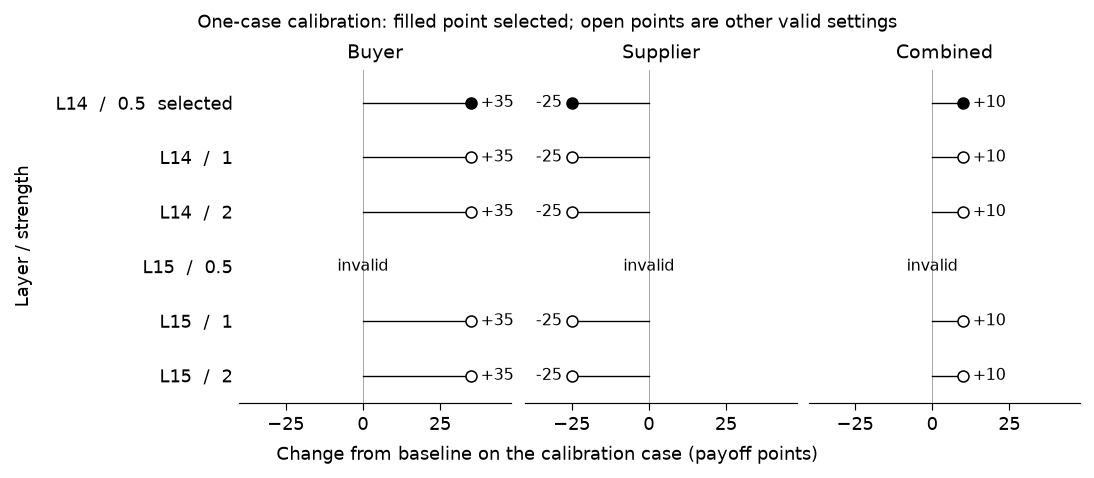

In [4]:
display(nb.candidates(calibration)[["Layer (zero-based)", "Strength", "Qualifies", "Selected", "Why"]])
nb.candidate_figure(calibration)
plt.show()

All five valid settings produced the same payoff changes: buyer +35, supplier -25 and combined +10. The declared tie-break selected strength +0.5, then the lower layer, 14. It did not select a larger effect or different counteroffer contents. One candidate failed because its answer was invalid. Both prompts produced the same counteroffer and payoffs as the selected edit. The construction examples' shared benefit had already failed to carry over on this case.

### Keep the unsuccessful attempts

Earlier attempts are part of the evidence. The first exposed a baseline ceiling; three later calibrations produced no eligible intended edit. A separate check failed a numerical tolerance and was followed by a diagnostic. Expanded construction then produced the candidate above. The table recalculates the four included calibration comparisons; the [history records](replay/evidence/history/) retain the exact attempt identifiers and earlier outcomes.

In [5]:
history_labels = {"a05": "Headroom correction", "a06": "Middle-layer comparison",
                  "a09": "Buyer-matched construction", "a10": "Expanded construction"}
display(nb.table([{"Calibration": history_labels[r["attempt"]], "Responses": r["attempts"],
                  "Valid": r["valid"], "Selected internal edit": r["selection"].get("selected_internal") or "None qualifies"}
                 for r in result["history"]]))

,Calibration,Responses,Valid,Selected internal edit
0,Headroom correction,41,41,None qualifies
1,Middle-layer comparison,41,41,None qualifies
2,Buyer-matched construction,41,41,None qualifies
3,Expanded construction,41,39,internal-14-0p5


## 3. Test the fixed candidate on new cases

The evaluation used **12 new scenario families, each with three wording variants**, for 36 cases. Nine conditions produced 324 responses: baseline, the selected edit, prompting, zero edit, three random edits, reverse direction and a permuted-label direction. Settings were fixed before generation. Before that run, the primary outcome was amended from proposed combined payoff to combined payoff after the supplier rule. Both outcomes remain in the analysis; calibration's original selection rule is unchanged.

Start with one case to see how a changed decision leads to a different consequence, then compare the complete case bank.

### Inspect one case, including both parties

The default is the **first declared evaluation case**, not a case selected for a favorable result. Change `CASE_ID` to any ID in `CASE_IDS` and rerun these cells. This explores saved responses; it does not ask the model a new question.

**prospective-20261031-pumps-base**

A water utility is buying replacement pumps for a scheduled maintenance shutdown.

,Condition,Valid,Decision,Terms,Buyer if agreed,Supplier if agreed,Agreement,Buyer after rule,Supplier after rule
0,Baseline,True,accept,Three weeks; 30 days; Medium price; Two years,42,49,True,42,49
1,Internal edit,True,offer,One week; 60 days; Low price; Two years,78,17,False,0,0
2,Prompting,True,offer,Three weeks; 30 days; Low price; Two years,64,29,False,0,0


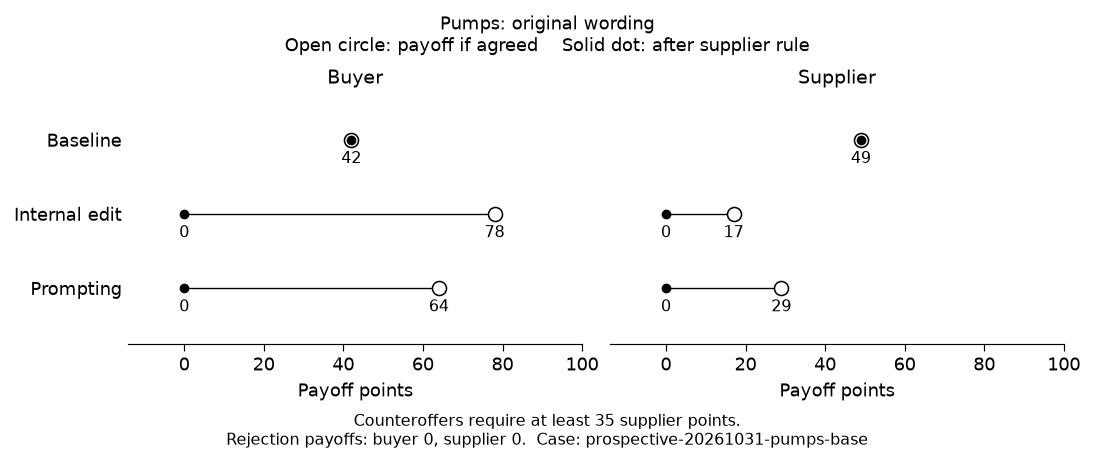

Baseline accepts the standing package, yielding 42 buyer points and 49 supplier points. Internal edit counteroffers, but its 17 supplier points do not meet the requirement of at least 35. Rejection leaves the buyer with 0 and the supplier with 0 points. Prompting counteroffers, but its 29 supplier points do not meet the requirement of at least 35. Rejection leaves the buyer with 0 and the supplier with 0 points.

In [6]:
cases = nb.read(ROOT / "replay/comparison/delivery/cases.json")
CASE_IDS = [case["case_id"] for case in cases]
CASE_ID = CASE_IDS[0]
scenario, case_results = nb.inspect_case(comparison, CASE_ID)
display(Markdown(f"**{CASE_ID}**\n\n{scenario}"))
display(case_results)
nb.case_figure(comparison, CASE_ID)
plt.show()
display(Markdown(nb.case_interpretation(comparison, CASE_ID)))

In [7]:
# Inspect exact responses, including invalid ones. Nothing is regenerated.
for condition in ("unchanged", "internal", "prompt"):
    row = next(r for r in comparison["all_trials"] if r["case_id"] == CASE_ID and r["condition"] == condition)
    print(nb.LABELS[condition], "| source:", row["source_log_path"])
    print(row["raw_response"], "\n")

Baseline | source: source-0000.json
{
  "decision": "accept",
  "package": {
    "price": "price1",
    "delivery": "delivery1",
    "warranty": "warranty1",
    "payment": "payment1"
  }
} 

Internal edit | source: source-0002.json
{
  "decision": "offer",
  "package": {
    "price": "price0",
    "delivery": "delivery0",
    "warranty": "warranty1",
    "payment": "payment2"
  }
} 

Prompting | source: source-0001.json
{
  "decision": "offer",
  "package": {
    "price": "price0",
    "delivery": "delivery1",
    "warranty": "warranty1",
    "payment": "payment1"
  }
} 



In [8]:
from html import escape
from IPython.display import HTML
prompts = nb.input_prompts(CASE_ID)
assert prompts["unchanged"] == prompts["internal"]
display(HTML("<details><summary>Complete input prompts for this case</summary><pre>" +
             escape(json.dumps(prompts, indent=2, ensure_ascii=False)) + "</pre></details>"))

### Compare all cases and conditions

The figure separates **counteroffers**, **agreements under the supplier rule**, and **invalid answers**. All panels use the same count scale. Accepting a standing offer and making a counteroffer are not interchangeable with reaching an agreement. Invalid answers remain in each condition's 36-attempt denominator. The three main comparisons appear above the controls.

,Condition,Attempts,Valid,Invalid,Counteroffers,Agreements,Buyer below reservation
0,Baseline,36,36,0,10,26,5
1,Prompting,36,31,5,22,14,2
2,Internal edit,36,33,3,23,10,1
3,Zero edit,36,36,0,10,26,5
4,Random 1,36,36,0,8,28,5
5,Random 2,36,36,0,9,27,5
6,Random 3,36,36,0,8,28,5
7,Reverse,36,36,0,0,36,12
8,Permuted,36,35,1,16,19,3


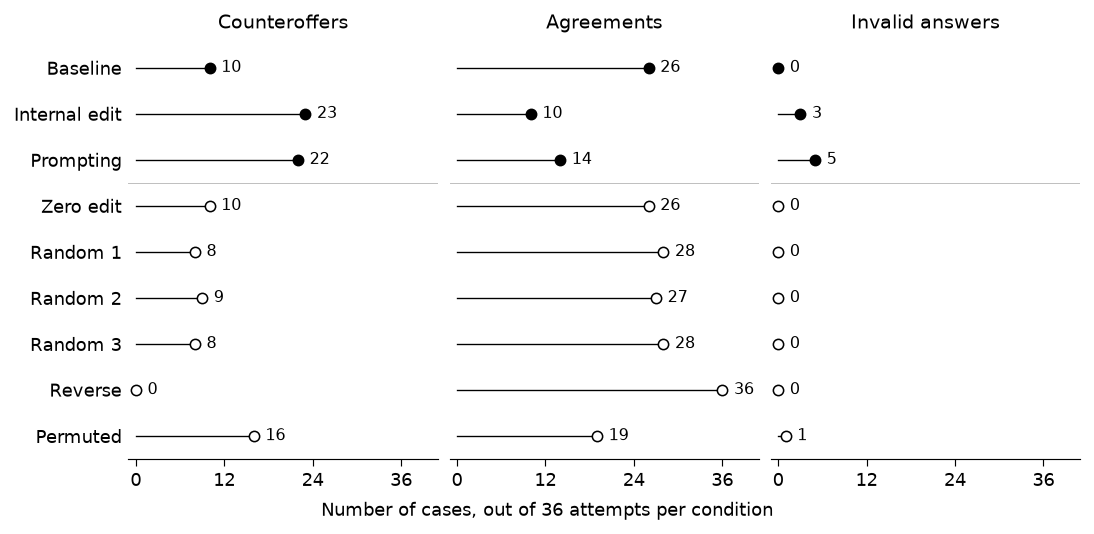

In [9]:
display(nb.condition_table(comparison))
nb.outcome_figure(comparison)
plt.show()

In [10]:
edit = next(r for r in comparison["accounting"] if r["condition"] == "internal")
print(f"The edit changed {edit['decision_changes']} of {edit['valid_pairs_with_baseline']} valid decisions.")
display(nb.table([{"Comparison": nb.LABELS[r["left"]] + " minus " + nb.LABELS[r["right"]],
                  "Valid pairs": r["valid_pairs"], "Decision or terms changed": r["decision_or_package_changed"],
                  "Higher combined payoff": r["higher_adjusted_joint_payoff"],
                  "Lower combined payoff": r["lower_adjusted_joint_payoff"]}
                 for r in result["independent_check"]["same_case_comparisons"]]))

The edit changed 13 of 33 valid decisions.


,Comparison,Valid pairs,Decision or terms changed,Higher combined payoff,Lower combined payoff
0,Internal edit minus Baseline,33,13,0,13
1,Internal edit minus Prompting,31,17,0,4
2,Prompting minus Baseline,31,19,2,10


The edit increased counteroffering but reduced agreements. Across the 13 changed valid cases, its offers requested an average of **31.6 more points for the buyer and 44.3 fewer for the supplier**; six gave the supplier zero proposed points. All 23 valid edited counteroffers, including the 13 additional ones, were rejected. Prompting produced the only five accepted counteroffers, with two improving combined payoff over baseline. These are decision and payoff findings, not evidence of a general cooperation trait. The controls remain separate comparisons, not replacement candidates.

## 4. Assess robustness and interpret the result

### Does the effect survive different wording?

Each row below holds the scenario and payoff structure fixed. Columns change its presentation. A solid dot shows a loss under the edit; an open circle shows no difference. “Invalid” means the payoff difference is undefined, not zero. The same horizontal scale in every panel separates variation across scenarios from sensitivity to how the same scenario is phrased.

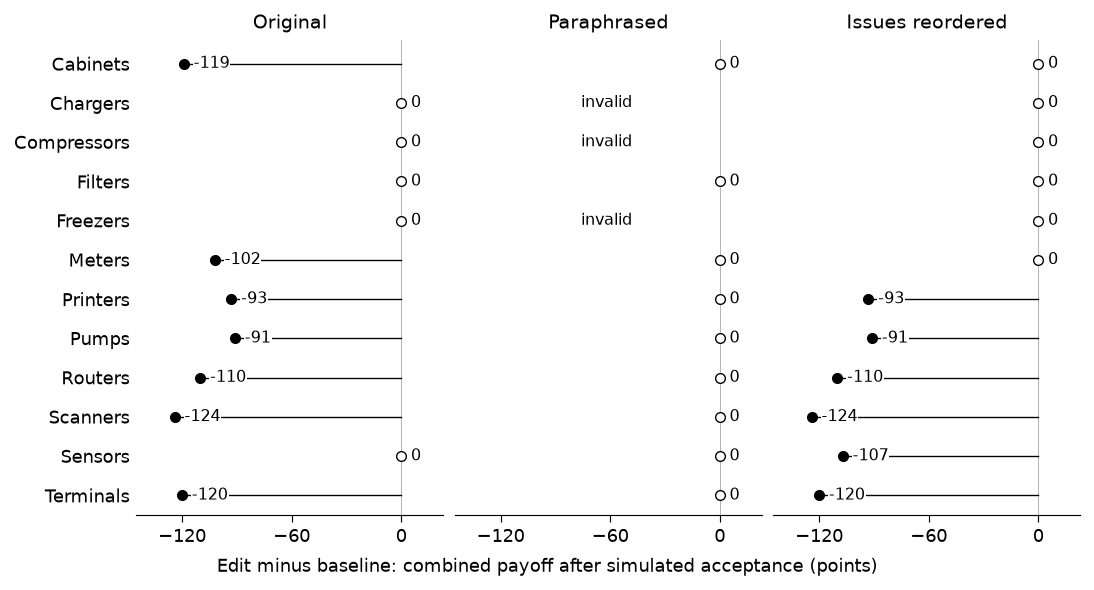

In [11]:
nb.wording_figure(comparison)
plt.show()

The selected edit changes 7/12 valid decisions under original wording and 6/12 when issues are reordered. Under paraphrasing, none of the nine valid edited decisions changes; three edited answers are invalid. This intervention is **wording-sensitive**. The paraphrase changed both the scenario sentence and the response-selection instruction. All nine invalid answers across the comparison used unsupported decision labels. This makes an explicit, fixed output schema a practical requirement for future wording tests.

### Does an identical prompt reproduce the same behavior?

**Verified identical-prompt repeatability.** Two complete fresh sessions repeated the 12 original-wording cases with baseline, the fixed edit and the fixed prompt. All **72/72 responses** matched the original decisions, terms, validity, acceptance and payoffs. All **24/24 case-level baseline-versus-edit contrasts** matched. Text, generated tokens and recorded processed logits also matched exactly for all 72 responses. Each session reproduced the original edit's 7/12 decision changes.

The table below recounts the audited records. The audit checked original Inspect logs, tokenization, weights, runtime, applied edits, restoration and all 602 delivered files. One earlier session timed out after 32 completed responses. It remains a failed attempt, with its records preserved, and is not counted as a complete repeat. The two complete sessions are retained R01 session 2 and the separately approved R02 completion.

This establishes repeatability for the same prompts and frozen greedy settings. The repeated outputs are not new independent scenarios. The wording sensitivity and negative payoff finding remain unchanged. This notebook reads the records; it does not poll a provider or generate responses.

In [12]:
display(nb.repeatability(output_dir=ROOT / "exports"))

,Session,Behavior,Text,Tokens,Processed logits,Edit contrasts
0,Fresh session 1,36/36,36/36,36/36,36/36,12/12
1,Fresh session 2,36/36,36/36,36/36,36/36,12/12


## 5. Adapt the procedure to another study

The reusable parts are the sequence of research decisions, condition accounting, scoring interface, saved-response records and comparison displays. Cases, substantive outcomes, compatible edit sites and scoring rules still depend on the study.

| Research decision | What to specify before evaluation |
|---|---|
| Intended change | The observable behavior, its rationale, and outcomes that must not deteriorate. |
| Construction and access | Compatible model and exact state location; contrasting examples, extraction position and edit schedule. |
| Candidate comparison | A finite layer/strength grid on development cases, selection rule, tie break and a legitimate “none qualifies” outcome. |
| New-case test | Held-out scenarios; baseline, prompt and declared controls; all attempts retained. |
| Robustness | Wording, presentation, repeated sessions and scoring checks; distinguish tested dimensions from untested models or constructions. |
| Interpretation | Decision change, downstream benefits, invalidity and technical failure reported separately. |

### A small reuse exercise, not a second empirical finding

The code below uses the **same saved-response workflow** with a different dataset and scorer: distributing units between two teams. Change the budget or authored answers in the cell and rerun it. At the starting budget of 100, the first two answers are valid and the third exceeds the budget. This tests the scoring interface, using no LLM.

In [13]:
sys.path.insert(0, str(ROOT / "replay/code"))
from review_package.workflow import AllocationScorer

BUDGET = 100
AUTHORED_RESPONSES = {
    "baseline": {"team_a": 70, "team_b": 30},
    "variant": {"team_a": 50, "team_b": 50},
    "invalid-example": {"team_a": 80, "team_b": 50},
}
SCORER = AllocationScorer()  # Replace with a scorer implementing score(case, raw).
synthetic = nb.synthetic_example(BUDGET, AUTHORED_RESPONSES, SCORER)
assert synthetic["empirical_evidence"] is False
display(nb.table([{"Condition": r["condition"], "Valid": r["valid"], **r["outcomes"]} for r in synthetic["rows"]]))

,Condition,Valid,team_a,team_b,absolute_gap
0,baseline,True,70.0,30.0,40.0
1,variant,True,50.0,50.0,0.0
2,invalid-example,False,Not defined,Not defined,Not defined


**Try it:** which check should reject `{"team_a": 80, "team_b": 50}` when the budget is 100? What additional outcome would distinguish equal division from an allocation appropriate to different needs?

The scorer checks nonnegative integer amounts and their total. Its absolute allocation gap is a numerical outcome, not a definition of fairness. Try a budget of 130: the deliberately invalid answer becomes valid and the other two cease to exhaust the budget.

For a new saved-response task, use `Study`, a scorer's `score(case, raw)` method, and `evaluate_saved` in [workflow.py](replay/code/review_package/workflow.py). The negotiation inputs are in [cases.json](replay/comparison/delivery/cases.json); its deterministic scoring is implemented in [scoring.py](replay/code/review_package/scoring.py) using the retained negotiation scorer. [SCHEMAS_AND_EXPORTS.md](SCHEMAS_AND_EXPORTS.md) identifies the case contract, outcome fields and source links. Copy these inputs for an adaptation; preserve the empirical example as supplied.

For model generation on a new task, use the separate execution source and requalify task competence, state editing and restoration. An ordinary answer-only API key cannot provide arbitrary access to internal states. The default notebook requires neither an API key nor GPU access.

## 6. Export, reproduce and extend

The exports below include every evaluation attempt, raw response, score, condition and source reference. Candidate exports retain eligibility, rejection reasons, direction geometry and realized-displacement summaries. The bundled source files and their SHA256 manifest let a reviewer trace the analysis to the preserved records.

In [14]:
display(Markdown("[All 324 evaluation attempts](exports/evaluation_attempts.csv)"))
display(Markdown("[All 41 calibration attempts](exports/calibration_attempts.csv)"))
display(Markdown("[Full findings and settings](exports/findings.json)"))
display(Markdown("[Independent payoff recalculation](exports/independent_check.json)"))
display(Markdown("[All 72 repeatability responses](exports/repeatability_outputs.csv)"))
display(Markdown("[Repeatability summary and audit sources](exports/repeatability_summary.json)"))

[All 324 evaluation attempts](exports/evaluation_attempts.csv)

[All 41 calibration attempts](exports/calibration_attempts.csv)

[Full findings and settings](exports/findings.json)

[Independent payoff recalculation](exports/independent_check.json)

[All 72 repeatability responses](exports/repeatability_outputs.csv)

[Repeatability summary and audit sources](exports/repeatability_summary.json)

### Roadmap

| Status | Capability |
|---|---|
| Implemented here | CPU replay of verified selection and new-case findings; figures; individual responses; all-attempt exports; a synthetic scorer-reuse exercise. |
| Research evidence available | One Qwen3.5-9B intervention, exploratory construction/calibration, one fixed 324-response evaluation, and two verified identical-prompt repeats totaling 72 responses. |
| Stage 2: own studies | Adapt cases and scorers without changing the common workflow; assess reuse through independent researchers and record the help they need. Pilot selection is open. |
| Stage 2: intervention validation | Compare candidates across development cases, freeze a selection, and test held-out cases. Keep response formats fixed in wording tests and check intended behavior, side effects and competence separately. |
| Stage 2: measurement | Develop a recorded-state measure and validate it against external references and simpler text-based alternatives. |
| Optional later interface | A web app for the same workflow, survey integration and MCP support. The website is not required for Stage 1. |

### Compute and time

Saved-response replay is CPU-only; the measured local time is recorded in `verification/verified_notebook.json`. The original 324-response study used one L40S GPU, eight CPU cores and 64 GiB RAM. Its response-completion span was 3 h 35 min, excluding startup; allow 4–5 GPU hours for a comparable run. The prior estimate was US$11–15 at the recorded October 31 rates, not an invoice or a guaranteed future price. The two complete 36-response repeats took 24 min 26 s and 42 min 44 s from first trial start to final completion, excluding setup and retrieval. R01 reserved US$10 for two sessions with a 40-minute worker limit and 45-minute container limit; one timed out. R02 separately reserved US$5 with a 60-minute worker limit and 65-minute container limit. These are reservations, not final charges.

`REPRODUCIBILITY.md` distinguishes analysis replay from generation reproduction. Default execution recalculates existing evidence; it never silently triggers the latter.

### API keys and optional GPU setup

**For everything above: no key is required.** This notebook reads the bundled records and runs local calculations.

For a separately configured GPU run, `.env.example` provides empty placeholders for `MODAL_TOKEN_ID` and `MODAL_TOKEN_SECRET`. An optional `HF_TOKEN` is relevant only if a model or download route requires Hugging Face authentication. These are credentials for compute and checkpoint access, not ordinary chat-model API keys. Answer-only API access does not expose the internal state edited in this study.

Read `GPU_SETUP.md` for the separate generation route. Use your provider's authenticated setup or an ignored `.env` file. Keep credentials out of notebook cells, outputs and Git. The roadmap describes the planned support for researchers' own model runs.

## Optional technical detail: payoff bounds and control contrasts

This section reports both parties' outcomes and the original and amended payoff analyses. The table gives differences from baseline, averaging valid paired variants within family and then the twelve families equally. With invalid responses these are **valid-subset descriptions**, not full-bank estimates. The internal edit's +11.42/-16.00 proposed changes therefore differ from the +31.6/-44.3 means conditional on the 13 changed cases.

In [15]:
display(nb.party_payoffs(comparison).round(2))

,Condition,Valid pairs,Proposed buyer,Proposed supplier,Buyer after rule,Supplier after rule
0,Internal edit,33,11.42,-16.00,-19.75,-19.25
1,Prompting,31,2.44,-2.85,-11.33,-12.46
2,Zero edit,36,0.00,0.00,0.00,0.00
3,Random 1,36,-1.11,1.94,3.44,3.17
4,Random 2,36,-0.39,1.08,1.81,1.50
5,Random 3,36,-1.11,1.94,3.44,3.17
6,Reverse,36,-14.25,14.56,10.58,16.94
7,Permuted,35,5.03,-7.47,-8.83,-10.22


The reversed edit raises agreement-adjusted joint payoff by 27.53 points, but 17.61 points of that gain come from the twelve cases where it accepts an offer below the buyer's own minimum. It remains a control, not a replacement treatment. The permuted direction's cosine with the target is 0.263; this is geometric alignment, not a percentage of shared meaning.

On the original proposed-combined-payoff outcome, missing-outcome bounds are [-5.86, -1.42] for edit minus baseline and [-9.81, 1.69] for edit minus prompting. The outcome amendment was made before generation, not after seeing these results.

Three edited answers and five prompted answers were invalid. Full-bank point estimates are therefore not reported for these contrasts. Instead, the saved analysis assigns every invalid answer the lowest and highest payoff permitted by its case and calculates bounds. Even the assignments most favorable to the edit leave its agreement-adjusted combined payoff below both baseline and prompting.

The lines below are **missing-outcome bounds, not confidence intervals**. They describe the fixed case bank. The table retains all control comparisons.

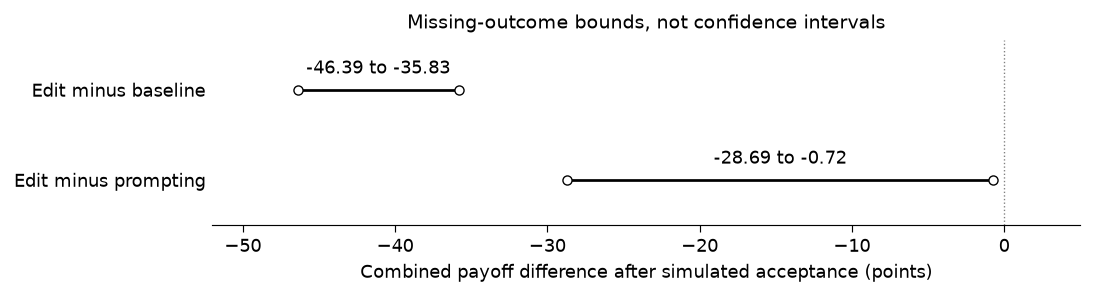

,Comparison,Valid pairs / 36,Mean difference,Missing-outcome bounds,Family-resampling interval,Variation note
0,Internal edit minus Baseline,33,Not identified,"[-46.39, -35.83]",Not defined,
1,Internal edit minus Prompting,31,Not identified,"[-28.69, -0.72]",Not defined,
2,Zero edit minus Baseline,36,0.0,"[0.00, 0.00]","[0.00, 0.00]",No variation across families in this case bank
3,Random 1 minus Baseline,36,6.61,"[6.61, 6.61]","[0.00, 16.53]",
4,Random 2 minus Baseline,36,3.31,"[3.31, 3.31]","[0.00, 9.92]",
5,Random 3 minus Baseline,36,6.61,"[6.61, 6.61]","[0.00, 16.53]",
6,Reverse minus Baseline,36,27.53,"[27.53, 27.53]","[11.06, 44.25]",
7,Permuted minus Baseline,35,Not identified,"[-21.28, -17.67]",Not defined,


In [16]:
nb.bounds_figure(comparison)
plt.show()
display(nb.contrast_table(comparison))

Family-bootstrap percentile intervals, where an outcome exists for every pair, describe sensitivity to resampling this case bank. A zero-width interval means no observed variation across its families, not perfect population precision. The [artifact status](ARTIFACT_STATUS.md) links the completed audits and separates these findings from planned reuse tests.